# ADVENTIST UNIVERSITY OF CENTRAL AFRICA (AUCA)

## Week 10 Lab — Machine Learning & Dashboards

**Course Name:**  Introduction to Big Data Analytics  
**Student ID:** 29061  
**Student Name:** Mutangana Joseph  

---


## Load week10_students.csv dataset

In [1]:
import pandas as pd
df=pd.read_csv("week10_students.csv")

## Part 1 · Explore & Split

**Exercise 1.1 — Know your data**

In [2]:
print(f"Shape of dataframe: {df.shape}")
print(f"Correlatin of score and quiz: {round(df["score"].corr(df["quiz_avg"]),3)}")
print(f"Correlatin of score and assignment_avg: {round(df["score"].corr(df["assignments_avg"]), 3)}")
print(f"Correlatin of score and attendance: {round(df["score"].corr(df["attendance_pct"]), 3)}")

# quiz_avg looks most useful because it has the
# strongest positive correlation with score (0.801).

Shape of dataframe: (150, 9)
Correlatin of score and quiz: 0.801
Correlatin of score and assignment_avg: 0.536
Correlatin of score and attendance: 0.238


**Exercise 1.2 — Frame & split**

**a) Three features X and Y(score)**

In [3]:
X = df[["quiz_avg", "assignments_avg", "attendance_pct"]]
y = df["score"]

**b) Train test split**

In [4]:
from sklearn.model_selection import train_test_split
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(f"X train size: {len(X_train)}")
print(f"X test size: {len(X_test)}")
print(f"Y train size: {len(y_train)}")
print(f"y test size: {len(y_test)}")

X train size: 112
X test size: 38
Y train size: 112
y test size: 38


**c) Comment** <br>
The reason why 25% students were hidden, they ere hidden so the model don't know about them so we can use them to test the model how it predict their score.

## Part 2 · Regression — Predict the Score

**Exercise 2.1 — Train & read the model**

In [5]:
from sklearn.linear_model import LinearRegression
# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Print each feature and its coefficient
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.3f}")

print("Intercept:", round(model.intercept_, 3))   

quiz_avg: 0.579
assignments_avg: 0.365
attendance_pct: 0.113
Intercept: -4.428


**c) Comment**<br>
One extra quiz point is associated with approximately 0.579 extra exam points,<br>
assuming assignments and attendance remain unchanged.

**Exercise 2.2 — Judge it honestly**

In [6]:
# Make predictions
y_pred = model.predict(X_test)

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {round(mae,2)}")
print(f"R²: {round(r2, 2)}")

MAE: 3.33
R²: 0.89


**Comment**<br>
**MAE:** Our predictions differ from actual student scores by about 3.33 points on average.<br>
**R²:** Our model explains approximately 89% of the differences in students' scores.

**Exercise 2.3 — Predict a new student**

In [7]:
new_student = pd.DataFrame({"quiz_avg":[70], "assignments_avg":[75], "attendance_pct":[90]})
new_inveted = pd.DataFrame({"quiz_avg":[80], "assignments_avg":[65], "attendance_pct":[70]})

new_student_pred = model.predict(new_student)
new_inveted_pred = model.predict(new_inveted)

print(f"New student predicted score is: {round(new_student_pred[0],2)}")
print(f"Inveted predicted score is: {round(new_inveted_pred[0],2)}")

New student predicted score is: 73.66
Inveted predicted score is: 73.54


## Part 3 · Classification — Catch the At-Risk Students

**Exercise 3.1 — Build the target & train**

a) Count passed/fail counts

In [8]:
df["passed"] = (df["score"] >= 50).astype(int)
counts = df["passed"].value_counts()

print("Total passed:", counts.get(1, 0))
print("Total failed:", counts.get(0, 0))

Total passed: 131
Total failed: 19


b) Classification model

In [9]:

from sklearn.linear_model import LogisticRegression

X = df[["quiz_avg", "assignments_avg", "attendance_pct"]]
y = df["passed"]

X_train, X_test, yc_train, yc_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

classification_model = LogisticRegression(max_iter=1000)

classification_model.fit(X_train, yc_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

**Exercise 3.2 — The accuracy**

a) Model accuracy

In [10]:
predictions = classification_model.predict(X_test)
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(yc_test, predictions)
print(f"Model accuracy: {round(accuracy,2)}")

Model accuracy: 0.89


(b) Lazy baseline

In [11]:
baseline_accuracy = yc_test.mean()
print(f"Lazy baseline: {round(baseline_accuracy,2)}")

Lazy baseline: 0.89


(c) Confusion matrix

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(yc_test, predictions)
print(cm)

[[ 3  1]
 [ 3 31]]


## Comment
Although both models achieve approximately 89% accuracy,<br>
our Logistic Regression model is more useful because it correctly<br>
identifies 3 students who failed, while the lazy baseline<br>
predicts that everyone passes and identifies none of them.<br>

## Part 4 · Feature Engineering

**Exercise 4.1 — Does more information help?**

**Experiment 1 — Quiz average only**

In [17]:
X1 = df[["quiz_avg"]]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y, test_size=0.25, random_state=42
)

model1 = LinearRegression()
model1.fit(X1_train, y1_train)

pred1 = model1.predict(X1_test)

r2_1 = r2_score(y1_test, pred1)

**Experiment 2 — All three numeric features**

In [18]:
X2 = df[["quiz_avg", "assignments_avg", "attendance_pct"]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)

pred2 = model2.predict(X2_test)

r2_2 = r2_score(y2_test, pred2)

**Experiment 3 — Numeric features + program**

In [20]:
X3 = pd.get_dummies(
    df[["quiz_avg", "assignments_avg", "attendance_pct", "program"]],
    columns=["program"],
    dtype=int
)

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.25, random_state=42
)

model3 = LinearRegression()
model3.fit(X3_train, y3_train)

pred3 = model3.predict(X3_test)

r2_3 = r2_score(y3_test, pred3)

**Compare the three models**

In [21]:
print("Model 1 (Quiz only):", round(r2_1, 3))
print("Model 2 (All numeric):", round(r2_2, 3))
print("Model 3 (Numeric + Program):", round(r2_3, 3))

Model 1 (Quiz only): 0.624
Model 2 (All numeric): 0.887
Model 3 (Numeric + Program): 0.88


## Comment

Adding assignments_avg and attendance_pct improved the model significantly,<br>
increasing R² from 0.624 to 0.887.<br>

However, adding program did not improve the model; R² slightly decreased to 0.880.<br>

This teaches us that adding more features does not always improve a model.<br>

The usefulness of a feature matters more than simply having more features.<br>

## Part 5 · Ship a Dashboard

**Exercise 5.1 — The story in three charts**

In [23]:
import plotly.express as px

**(a) histogram of scores**

*Chart 1 — Where the class stands*

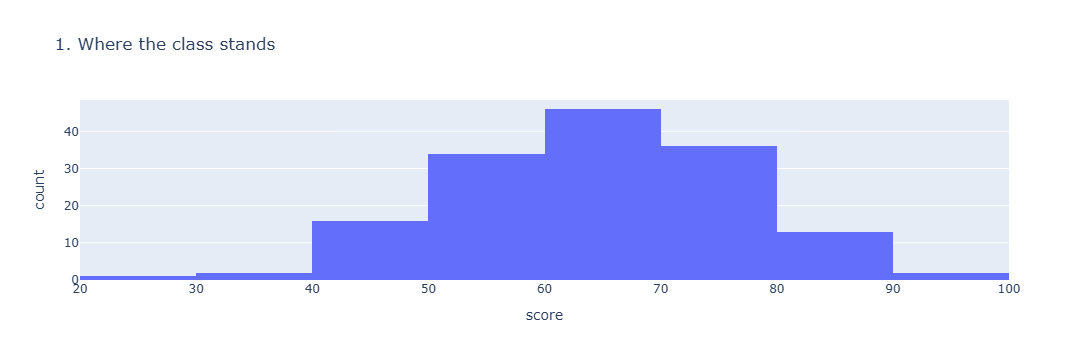

In [24]:
fig1 = px.histogram(
    df,
    x="score",
    nbins=12,
    title="1. Where the class stands"
)

fig1.show()

**(b) scatter quiz_avg vs score**

Chart 2 — Who is at risk

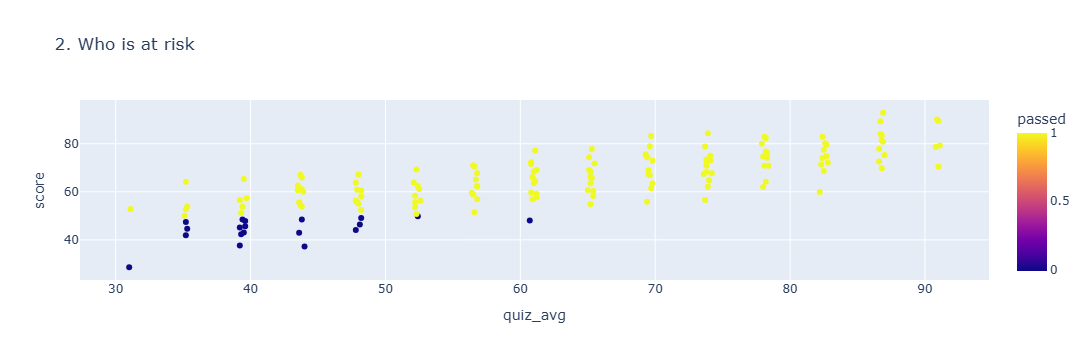

In [38]:
fig2 = px.scatter(
    df,
    x="quiz_avg",
    y="score",
    color="passed",
    hover_name="name",
    title="2. Who is at risk"
)

fig2.show()

**(c) bar chart of average score per district**

Chart 3 — Where to act

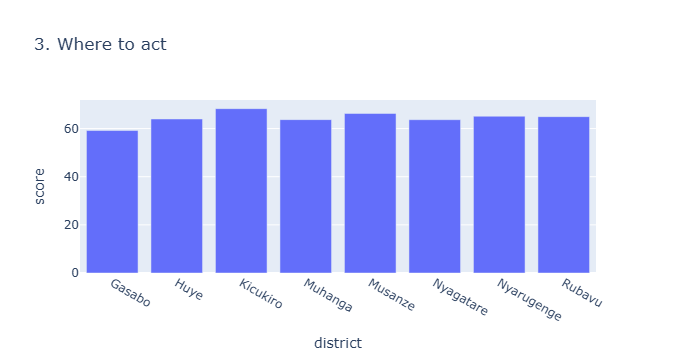

In [44]:
fig3 = px.bar(
    df.groupby("district", as_index=False)["score"].mean(),
    x="district",
    y="score",
    title="3. Where to act"
)

fig3.show()

**Exercise 5.2 — Publish it**

In [29]:
fig2.write_html("class_dashboard.html")

**Screeenshot of the class dashboard running in the browser**

![Class Dashboard](dashboard_screenshot.png)

**Bonus (+3) — One chart, four stories**

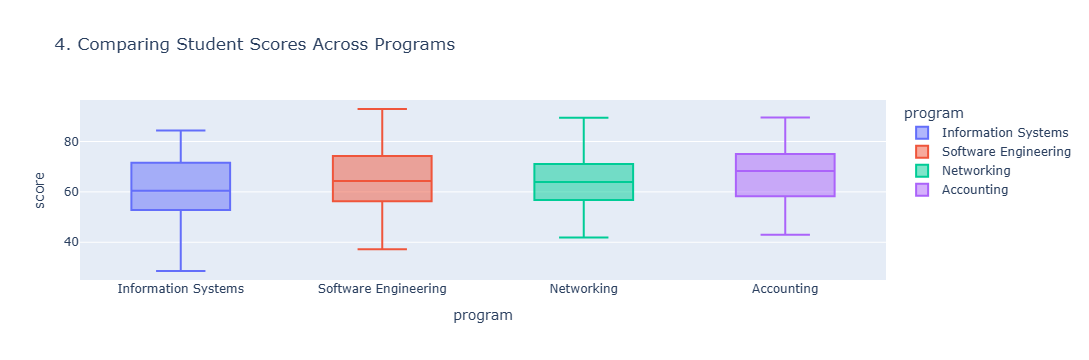

In [32]:
fig4 = px.box(
    df,
    x="program",
    y="score",
    color="program",
    title="4. Comparing Student Scores Across Programs"
)

fig4.show()

## Comment
**Information Systems:** Its middle 50% of student scores are more spread out. Students' scores vary more within that central group.

**Networking:** Its middle 50% of scores are closer together. Students have more consistent scores within that central group.